# 4주차 결과 시각화

가격 차트는 제외하고 누적 손익과 z-score를 확인했다. 결과 이미지는 `results/plots/`에 저장했다.

In [1]:
import os, sys, json, re
from collections import defaultdict
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

if Path.cwd().name == "week04":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

from core.bars import add_minutes
from core.config import load_json
from week04.backtest import load_leg, minute_prices, minutes_between, run_backtest
from week04.strategy import spread, zscore

plt.rcParams["font.family"] = "Apple SD Gothic Neo"
plt.rcParams["axes.unicode_minus"] = False

config = load_json("week04/config.json")
session = config["sessions"][config["selected_session"]]
period = config["backtest"]
slippage = period["slippage_ticks"]
legs = [load_leg(leg["symbol"], period) for leg in config["legs"]]
days = sorted(set(legs[0]) & set(legs[1]))

out = Path("week04/results/plots")
out.mkdir(parents=True, exist_ok=True)
len(days)

35

## 1. 본전 청산 규칙에 따른 누적 손익 비교

11/10 모의투자에서는 본전 청산 11건이 모두 손실로 끝났다. 백테스트에서도 같은 흐름이 나타나는지 규칙을 적용했을 때와 적용하지 않았을 때의 누적 손익을 비교했다.

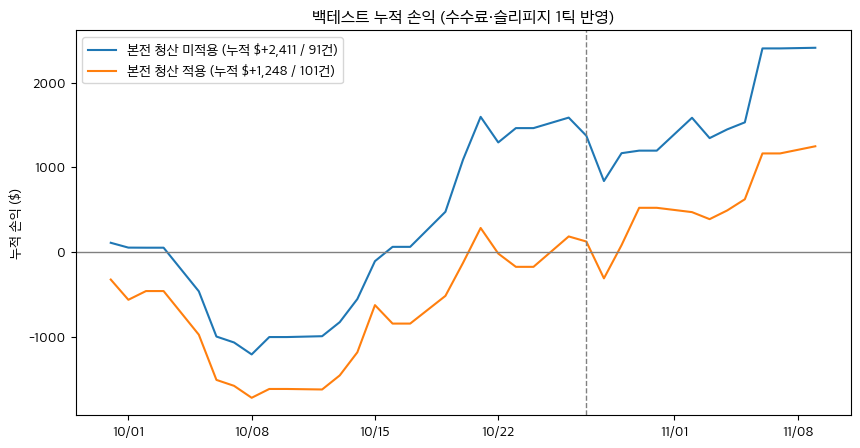

In [2]:
fig, ax = plt.subplots(figsize=(10, 5))

for version, label in [("base", "본전 청산 미적용"), ("with_breakeven", "본전 청산 적용")]:
    params = {**config["strategy"], **session, **config["versions"][version]}
    trades, _ = run_backtest(legs, days, params, config, slippage)

    by_day = defaultdict(float)
    for t in trades:
        by_day[t.date] += t.net

    total, xs, ys = 0, [], []
    for day in days:
        total += by_day[day]
        xs.append(datetime.strptime(day, "%Y%m%d"))
        ys.append(total)
    ax.plot(xs, ys, label=f"{label} (누적 ${total:+,.0f} / {len(trades)}건)")

ax.axhline(0, color="gray", linewidth=1)
ax.axvline(datetime.strptime(period["split_date"], "%Y%m%d"), color="gray", linestyle="--", linewidth=1)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d"))
ax.set_title("백테스트 누적 손익 (수수료·슬리피지 1틱 반영)")
ax.set_ylabel("누적 손익 ($)")
ax.legend()
fig.savefig(out / "1_backtest_equity.png", dpi=150, bbox_inches="tight")

## 2. 11/02 z-score와 진입·청산 시점

익절과 손절이 모두 나온 11/02를 골라 진입부터 청산까지의 흐름을 확인했다. 회색 실선은 0, 긴 점선은 진입 기준(±2), 짧은 점선은 손절 기준(±3)이다.

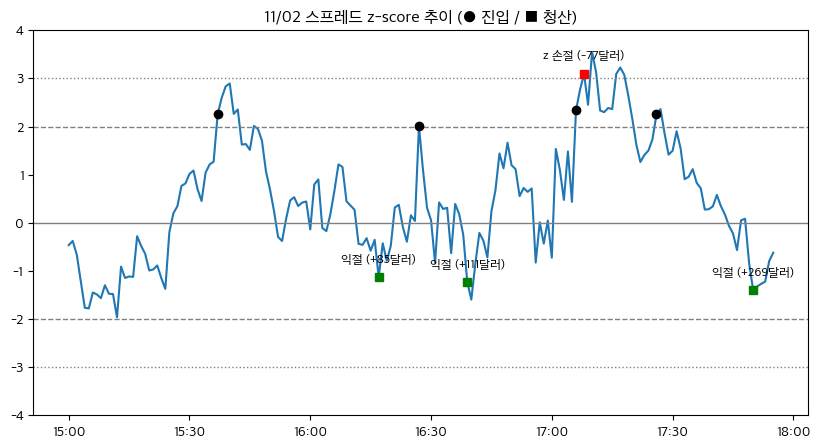

In [3]:
date = "20261102"
params = {**config["strategy"], **session, **config["versions"]["base"]}
trades, _ = run_backtest(legs, [date], params, config, slippage)

first = add_minutes(params["entry_start"], -(params["window"] + 5))
times = [add_minutes(first, i) for i in range(minutes_between(first, params["close_time"]) + 1)]
prices = [minute_prices(leg[date], times) for leg in legs]

spreads, z = [], {}
for time, (_, c1), (_, c2) in zip(times, prices[0], prices[1]):
    if c1 is None or c2 is None:
        continue
    spreads.append(spread(c1, c2))
    result = zscore(spreads, params["window"])
    if result and time >= params["entry_start"]:
        z[datetime.strptime(date + time, "%Y%m%d%H%M%S")] = result[0]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(list(z), list(z.values()))
for level in [2, -2]:
    ax.axhline(level, color="gray", linestyle="--", linewidth=1)
for level in [3, -3]:
    ax.axhline(level, color="gray", linestyle=":", linewidth=1)
ax.axhline(0, color="gray", linewidth=1)

for t in trades:
    entry = datetime.strptime(date + t.entry_time, "%Y%m%d%H%M%S")
    exit_ = datetime.strptime(date + t.exit_time, "%Y%m%d%H%M%S")
    ax.plot(entry, z[entry], "ko")
    ax.plot(exit_, z[exit_], "s", color="green" if t.net > 0 else "red")
    ax.annotate(f"{t.reason} ({t.net:+.0f}달러)", (exit_, z[exit_]), xytext=(0, 10),
                textcoords="offset points", ha="center", fontsize=9)

ax.set_ylim(-4, 4)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_title("11/02 스프레드 z-score 추이 (● 진입 / ■ 청산)")
fig.savefig(out / f"2_zscore_{date}.png", dpi=150, bbox_inches="tight")

## 3. 모의투자 거래별 손익

`events_*.jsonl`에서 청산 체결 내역만 추렸다. 11/10 모의투자는 본전 청산 규칙을 적용한 상태로 실행했다.

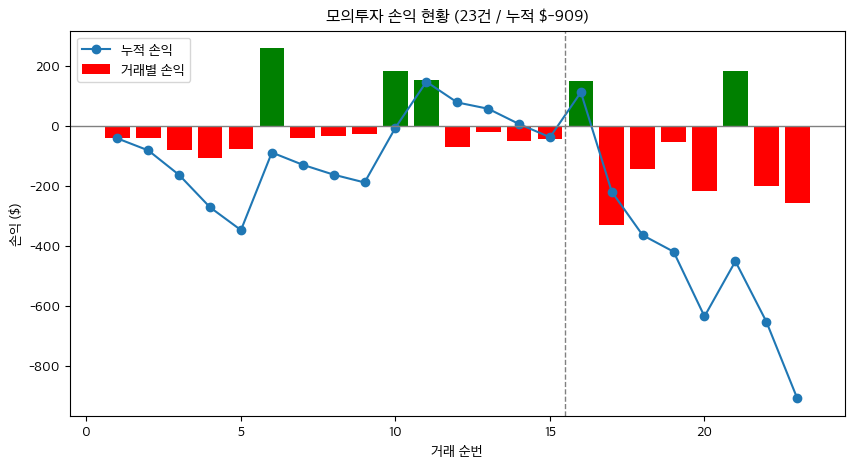

In [4]:
live = []
for path in sorted(Path("week04/results").glob("events_*.jsonl")):
    for line in path.read_text().splitlines():
        event = json.loads(line)
        if event["event"] == "청산 체결":
            net = float(re.match(r"\$([+-][\d,.]+)", event["data"]["손익"]).group(1).replace(",", ""))
            live.append((event["timestamp"], net))
live.sort()

nets = [net for _, net in live]
cumulative = [sum(nets[:i + 1]) for i in range(len(nets))]
x = range(1, len(nets) + 1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x, nets, color=["green" if n > 0 else "red" for n in nets], label="거래별 손익")
ax.plot(x, cumulative, marker="o", label="누적 손익")
ax.axhline(0, color="gray", linewidth=1)

days_ = [ts[:10] for ts, _ in live]
for i in range(1, len(days_)):
    if days_[i] != days_[i - 1]:
        ax.axvline(i + 0.5, color="gray", linestyle="--", linewidth=1)

ax.set_title(f"모의투자 손익 현황 ({len(nets)}건 / 누적 ${cumulative[-1]:+,.0f})")
ax.set_xlabel("거래 순번")
ax.set_ylabel("손익 ($)")
ax.legend()
fig.savefig(out / "3_live_pnl.png", dpi=150, bbox_inches="tight")